**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**04 | Unimodal Baselines and Classical EEG–Gaze Fusion**

![Classical unimodal and fusion model comparison](../../images/04_unimodal_baselines_and_classical_fusion.svg)

**Research question:** On the same participant-disjoint ZuCo 2.0 reading windows, do early feature fusion or fixed equal-weight late fusion improve on the strongest EEG-only or gaze-only model for classifying Normal Reading (NR) versus Task-Specific Reading (TSR)?

**Objective:** Train a class-prior reference, EEG-only and gaze-only logistic/forest models, early-fusion logistic regression and a fixed 0.50/0.50 late-probability fusion. Compare seven candidates using fixed-label Validation Macro F1 and Balanced Accuracy.

**Dataset and recorded inputs:** NEMAR ZuCo 2.0 (`nm000279`, `v1.0.0`); `02_window_registry.csv` and `03_features.csv` contain 206 matched 12-second paired windows with four EEG and four gaze summary features. Participant-disjoint roles are **95 Train windows (three people)**, **31 Validation windows (one person)** and **80 reserved Test windows (two people)**.

**Executed scope and outputs:** Six train-fitted estimators and the fixed late-fusion rule were evaluated on Validation only. The current `04_validation_metrics.csv`, `04_validation_predictions.csv`, `04_*.joblib`, `04_late_fusion.json` and two Validation plots record the results. Test predictions and scores were not produced.

**Interpretative boundary:** The outcome is a documented reading-task instruction, not comprehension or a directly measured cognitive state. One Validation participant does not establish general performance across unseen people.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Machine Learning and Deep Learning -------------------
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from models import (
    CLASSICAL_ORDER, CLASS_TO_INDEX, estimator, matrix, metrics,
    probabilities, record_predictions,
)

# ---------------------------- 8. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 9. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 106.29


**02. Load and Verify the Recorded Feature Table**

Read the exact `03_features.csv` rows produced in Notebook 03 and reconcile their original window IDs, tasks and participant roles with the saved `02_window_registry.csv`.

**Recorded upstream evidence:** **206 matched windows**, no missing mean feature values, no extra exclusions and a fixed 95/31/80 Train/Validation/Test partition. Keep the reserved Test table only for a transparent partition count; **no Test predictions, labels or scores** enter estimator fitting or Validation comparison.


In [3]:
# ============== 02. Load Paired Feature Table and Fixed Labels ===============

required = ["02_window_registry.csv", "03_features.csv"]
missing = [name for name in required if not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"Missing upstream paired-window or feature outputs: {missing}"
    )

table = pd.read_csv(
    output_dir / "03_features.csv", dtype={"participant_id": str}
)
registry = pd.read_csv(
    output_dir / "02_window_registry.csv", dtype={"participant_id": str}
)
expected = registry.loc[
    registry.eligible, ["window_id", "participant_id", "task", "split"]
]
if table.empty or table.window_id.duplicated().any():
    raise ValueError("Feature table is empty or contains duplicate windows")
if expected.window_id.duplicated().any():
    raise ValueError("Stage-02 eligible window identities are duplicated")
if set(table.window_id) != set(expected.window_id):
    raise ValueError(
        "Stage-03 feature windows differ from the fixed Stage-02 registry"
    )
matched = table[
    ["window_id", "participant_id", "task", "split"]
].merge(
    expected, on="window_id", how="left",
    validate="one_to_one", suffixes=("_feature", "_registry"),
)
for field in ("participant_id", "task", "split"):
    if (matched[f"{field}_registry"].isna().any() or not
            matched[f"{field}_feature"].eq(
                matched[f"{field}_registry"]
            ).all()):
        raise ValueError(
            f"Stage-03 {field} fields differ from the source window registry"
        )
if not table.groupby("participant_id")["split"].nunique().eq(1).all():
    raise ValueError("A participant appears in multiple split roles")
if not set(table.task).issubset(CLASS_TO_INDEX):
    raise ValueError("Unexpected reading task labels")

train = table.loc[table.split.eq("train")].copy()
valid = table.loc[table.split.eq("validation")].copy()
test = table.loc[table.split.eq("test")].copy()
if min(len(train), len(valid), len(test)) < 1:
    raise ValueError("The original partition has an empty role")
if train.task.nunique() != 2 or valid.task.nunique() != 2:
    raise ValueError("Both task classes must appear in Train and Validation")
y_train = train.task.map(CLASS_TO_INDEX).to_numpy()
y_valid = valid.task.map(CLASS_TO_INDEX).to_numpy()

print("Matched paired feature windows:", len(table))
print("Train:", len(train), "windows /", train.participant_id.nunique(),
      "people")
print("Validation:", len(valid), "windows /",
      valid.participant_id.nunique(), "people")
print("Reserved Test:", len(test), "windows /",
      test.participant_id.nunique(), "people (not scored)")
display(
    table.groupby(["split", "task"])
    .agg(windows=("window_id", "size"),
         people=("participant_id", "nunique"))
    .reset_index()
)


Matched paired feature windows: 206
Train: 95 windows / 3 people
Validation: 31 windows / 1 people
Reserved Test: 80 windows / 2 people (not scored)


,split,task,windows,people
0,test,nr,40,2
1,test,tsr,40,2
2,train,nr,41,3
3,train,tsr,54,3
4,validation,nr,20,1
5,validation,tsr,11,1


**03. Fit the Class Prior and Unimodal Models**

Fit the class-prior baseline, EEG-only and gaze-only regularised logistic regressions, and separate EEG/gaze random forests using **Train windows only**.

The class-prior baseline ignores all EEG/gaze predictors and reflects only the Train label distribution. The modality models use fixed configurations and Train-fitted imputation/scaling as implemented. Participant identifiers, timestamps, Run numbers and task labels are not included among predictor columns.

**Caution:** The `gaze_valid_fraction` feature is constant at 1.000 in the recorded data and does not carry variation for this cohort.


In [4]:
# ============ 03. Fit Task Prior and Separate Unimodal Estimators ============

fitted, predictions, records = {}, {}, []
feature_group = {
    'class_prior': 'gaze',
    'gaze_logistic': 'gaze', 'eeg_logistic': 'eeg',
    'early_fusion_logistic': 'fused',
    'gaze_forest': 'gaze', 'eeg_forest': 'eeg',
}
for name in CLASSICAL_ORDER:
    if name == 'late_equal_fusion':
        continue
    group = feature_group[name]
    model = estimator(name, seed=SEED)
    x_train = matrix(train, group)
    x_val = matrix(valid, group)
    model.fit(x_train, y_train)
    proba = probabilities(model, x_val)
    fitted[name] = model
    predictions[name] = proba
    row = {'model': name, 'partition': 'validation',
           'n_windows': len(valid),
           'n_people': valid.participant_id.nunique(),
           **metrics(y_valid, proba.argmax(axis=1))}
    records.append(row)
    joblib.dump(model, output_dir / f'04_{name}.joblib')
    print(name, 'Macro F1:', round(row['macro_f1'], 4))


class_prior Macro F1: 0.2619
gaze_logistic Macro F1: 0.8862
eeg_logistic Macro F1: 0.1622
early_fusion_logistic Macro F1: 0.562
gaze_forest Macro F1: 0.6601
eeg_forest Macro F1: 0.2955


**04. Evaluate Early and Fixed Late Fusion**

Early Fusion concatenates the same window's EEG and gaze mean features, then fits a Train-only logistic pipeline. Late Fusion averages the already trained EEG-logistic and gaze-logistic class probabilities using fixed **0.50/0.50** weights.

Both methods are scored on the **same 31 Validation windows** as their unimodal comparators. The late-fusion weights are specified in advance; they are not optimised using Validation or Test.


In [5]:
# ============ 04. Fit Early Fusion and Evaluate Fixed Late Fusion ============

late = 0.5 * (predictions['gaze_logistic'] +
              predictions['eeg_logistic'])
predictions['late_equal_fusion'] = late
records.append({
    'model': 'late_equal_fusion', 'partition': 'validation',
    'n_windows': len(valid),
    'n_people': valid.participant_id.nunique(),
    **metrics(y_valid, late.argmax(axis=1))
})
(output_dir / '04_late_fusion.json').write_text(
    json.dumps({'weight_eeg': 0.5, 'weight_gaze': 0.5,
                'components': ['eeg_logistic', 'gaze_logistic']},
               indent=2), encoding='utf-8')
summary = pd.DataFrame(records)
if set(summary.model) != set(CLASSICAL_ORDER):
    raise ValueError("Missing or duplicate classical candidate names")
display(summary.sort_values('macro_f1', ascending=False))


,model,partition,n_windows,n_people,accuracy,macro_f1,balanced_accuracy
1,gaze_logistic,validation,31,1,0.903226,0.886169,0.863636
6,late_equal_fusion,validation,31,1,0.806452,0.778571,0.768182
4,gaze_forest,validation,31,1,0.677419,0.660088,0.668182
3,early_fusion_logistic,validation,31,1,0.709677,0.562009,0.590909
5,eeg_forest,validation,31,1,0.354839,0.295455,0.295455
0,class_prior,validation,31,1,0.354839,0.261905,0.500000
2,eeg_logistic,validation,31,1,0.193548,0.162162,0.272727


**05. Compare Validation Metrics and Predictions**

The seven saved candidates were evaluated on the same **31 Validation windows from one participant** (20 NR and 11 TSR). Scores use both NR and TSR in fixed-label Macro F1, with Balanced Accuracy and Accuracy reported separately. The bar plot shows all candidates; the confusion matrix shows the Validation leader selected for illustration, **not a final Test-selected model**.

**Recorded result:** Gaze-only logistic regression led this classical comparison (Macro F1 **0.8862**, Balanced Accuracy **0.8636**). Fixed late fusion reached **0.7786** Macro F1, and early-fusion logistic regression reached **0.5620**. Neither fusion candidate improved over gaze logistic regression in this Validation sample.

These are repeated windows from **one independent person**, not 31 independent participants. The source task and text conditions, acquisition quality and possible ocular contributions to EEG can affect this comparison; no general fusion advantage or disadvantage is established.


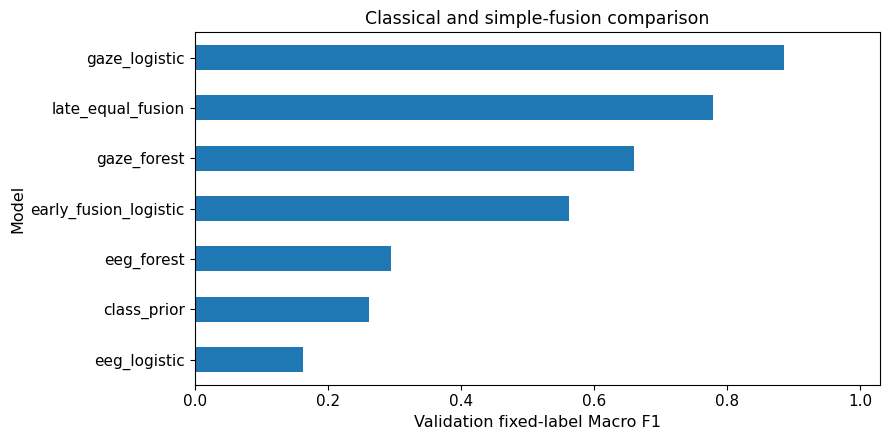

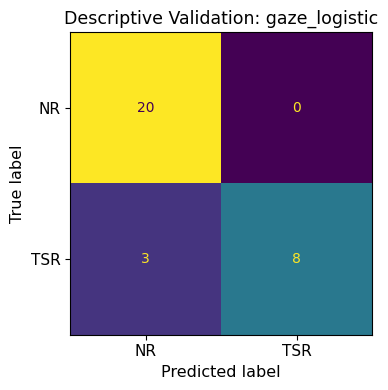

In [6]:
# =========== 05. Compare Validation Metrics and a Confusion Matrix ===========

fig, ax = plt.subplots(figsize=(9, 4.5))
summary.sort_values('macro_f1').plot.barh(
    x='model', y='macro_f1', ax=ax, legend=False)
ax.set(xlabel='Validation fixed-label Macro F1',
       ylabel='Model', xlim=(0, 1.03),
       title='Classical and simple-fusion comparison')
fig.tight_layout()
fig.savefig(output_dir / '04_validation_comparison.png', dpi=170)
plt.show()
best = summary.sort_values(['macro_f1', 'balanced_accuracy'],
                           ascending=False).iloc[0].model
fig, ax = plt.subplots(figsize=(4.3, 4))
ConfusionMatrixDisplay.from_predictions(
    y_valid, predictions[best].argmax(axis=1),
    labels=[0, 1], display_labels=['NR', 'TSR'], ax=ax,
    colorbar=False)
ax.set_title(f'Descriptive Validation: {best}')
fig.tight_layout()
fig.savefig(output_dir / '04_validation_confusion.png', dpi=170)
plt.show()


**06. Save Comparable Validation Evidence**

The recorded `04_validation_predictions.csv` contains **217 prediction rows**: seven candidates × the same **31 original Validation `window_id` values**. Each row retains participant, task, fixed class indices and the `p_nr`/`p_tsr` probabilities. The saved predictions match the Stage-02/03 identifiers, labels and Validation split; recomputed Accuracy, fixed-label Macro F1 and Balanced Accuracy agree with the seven rows of `04_validation_metrics.csv`.

The six `04_*.joblib` files contain Train-fitted estimators; `04_late_fusion.json` records the fixed 0.50/0.50 mixture. `04_validation_comparison.png` and `04_validation_confusion.png` are descriptive Validation figures. No Test predictions or Test metrics belong to Stage 04.


In [7]:
# ============== 06. Check Probabilities and Save Model Evidence ==============

saved = []
for name in CLASSICAL_ORDER:
    proba = predictions[name]
    if proba.shape != (len(valid), 2):
        raise ValueError(f"Invalid probability dimensions for {name}")
    if not np.isfinite(proba).all():
        raise ValueError(f"Non-finite model probabilities for {name}")
    if not np.allclose(proba.sum(axis=1), 1., atol=1e-5):
        raise ValueError(f"Non-normalised probabilities for {name}")
    saved.append(record_predictions(valid, name, proba))
prediction_table = pd.concat(saved, ignore_index=True)
prediction_table.to_csv(
    output_dir / '04_validation_predictions.csv', index=False)
summary.to_csv(output_dir / '04_validation_metrics.csv', index=False)
print('Validation rows:', len(prediction_table))
model_support = prediction_table.groupby("model")["window_id"].nunique()
if (not model_support.eq(len(valid)).all() or
        prediction_table.duplicated(["model", "window_id"]).any() or
        not prediction_table.window_id.isin(valid.window_id).all()):
    raise ValueError(
        "Saved candidate predictions do not match the fixed Validation IDs"
    )
print("Models with complete Validation predictions:", len(model_support))
print("Independent Validation participants:",
      valid.participant_id.nunique())


Validation rows: 217
Models with complete Validation predictions: 7
Independent Validation participants: 1


**07. Interpretation and Next Dependency**

The strongest classical Validation candidate was **gaze logistic regression**: Macro F1 **0.8862** and Accuracy **0.9032** on 31 windows from one held-out person. Its confusion matrix has **20/20 NR** and **8/11 TSR** correctly classified. Equal-weight late fusion scored **0.7786** Macro F1 and early fusion **0.5620**, below the strongest unimodal candidate. EEG-only models were weaker on this participant; this does not establish a general EEG disadvantage.

**Scientific interpretation:** These are exploratory, participant-disjoint **Validation** findings. Reading-task labels can be associated with text/stimulus differences, run conditions, gaze artefacts and ocular signal in EEG. The 31 windows are correlated within one person; no population-level fusion, comprehension, causal or clinical claim follows.

**Next dependency:** [Notebook 05](05_temporal_and_advanced_fusion.ipynb) uses `03_features.csv` and `03_temporal_sequences.npz` to train three compact GRU candidates on the same Train/Validation roles. Notebook 06 later compares all ten candidates using the prespecified Validation rule; its `RUN_FINAL_TEST=False` development default must remain unchanged unless final Test evaluation is separately authorised.


In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print('Next: 05_temporal_and_advanced_fusion.ipynb')
download_outputs_from_colab("eeg_eye_tracking_fusion/output", "04")


Next: 05_temporal_and_advanced_fusion.ipynb
------------------------------------------------------------------------
Notebook 04
Files packaged: 11
  + 04_class_prior.joblib
  + 04_early_fusion_logistic.joblib
  + 04_eeg_forest.joblib
  + 04_eeg_logistic.joblib
  + 04_gaze_forest.joblib
  + 04_gaze_logistic.joblib
  + 04_late_fusion.json
  + 04_validation_comparison.png
  + 04_validation_confusion.png
  + 04_validation_metrics.csv
  + 04_validation_predictions.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_04_Outputs.zip
